# 09 · 신약 타겟 발굴 — 오믹스·네트워크 데이터
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑪ 신약 타겟 발굴 (오믹스·네트워크 데이터)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/09_Target_Discovery_Omics_Network.ipynb)

| 항목 | 내용 |
|---|---|
| **질문** | **삼중음성유방암(TNBC, Basal-like)** 에서 새 치료 표적이 될 만한 유전자는? |
| **학습 목표** | ① 질병-유전자 연관 근거 통합(**Open Targets**) ② 전사체(RNA-seq) 차등발현 분석 — **volcano plot** ③ 머신러닝으로 아형 분류·바이오마커 ④ 단백질 상호작용(**PPI**) 네트워크 허브 분석 ⑤ **근거 통합 타겟 우선순위** |
| **데이터** | Open Targets Platform(유방암 연관 유전자 300) · **TCGA BRCA** RNA-seq(981명, PAM50 아형, cBioPortal) · **STRING** PPI |
| **실행 환경** | CPU · 약 5분 |

```
질병 연관 유전자(유전체·문헌·임상) → 환자 오믹스에서 차등발현 → 네트워크 허브 → 약물 개발 가능성(tractability) → 우선순위 → 구조(예제 08)·스크리닝(예제 07)
```

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib, os, io, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
import warnings; warnings.filterwarnings("ignore")
from scipy import stats

# 수업용 데이터 스냅샷(GitHub 저장소) — API 가 응답하지 않을 때도 실습이 진행되도록 준비
REPO = "https://raw.githubusercontent.com/StillWork/DrugAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 타겟 발굴의 근거(evidence) 유형
| 근거 | 데이터 | 질문 |
|---|---|---|
| **유전학** | GWAS, 희귀변이, 체세포 돌연변이(TCGA) | 유전자 변이가 질병 위험·발생과 연관되는가? (유전학 근거가 있는 표적은 임상 성공률 약 2배) |
| **발현(오믹스)** | RNA-seq, 단백체, 단일세포 | 환자 조직에서 비정상적으로 발현되는가? |
| **경로·네트워크** | PPI(STRING), 신호경로(Reactome) | 질병 네트워크의 중심(허브)인가? |
| **기능 검증** | CRISPR 스크린(DepMap), 동물모델 | 없애면 질병 세포가 죽는가? |
| **약물개발 가능성** | 구조, 결합 pocket, 기존 리간드 | 저분자/항체로 공략 가능한가? (tractability) |

## 1. Open Targets — 질병-타겟 연관 근거 통합
**Open Targets Platform**(EMBL-EBI·Wellcome Sanger·제약사 컨소시엄)은 유전학·체세포변이·문헌·임상·동물모델 근거를 통합한 **질병-타겟 연관 점수(0~1)** 를 제공합니다.
GraphQL API 로 '유방암(MONDO_0007254)' 연관 상위 300개 유전자를 가져옵니다.

In [2]:
query = '''query($efo:String!,$size:Int!){ disease(efoId:$efo){ name associatedTargets(page:{index:0,size:$size}){ count
  rows{ score target{ id approvedSymbol approvedName } datatypeScores{ id score } } } } }'''
try:
    r = requests.post("https://api.platform.opentargets.org/api/v4/graphql",
                      json={"query": query, "variables": {"efo": "MONDO_0007254", "size": 300}}, timeout=60)
    d = r.json()["data"]["disease"]
    print(f"[실시간 API] '{d['name']}' 연관 유전자 총 {d['associatedTargets']['count']:,}개 중 상위 300개 수신")
except Exception as e:
    print("Open Targets API 응답 없음 → 스냅샷 사용:", e)
ot = load_data("opentargets_breast_cancer.csv")      # 같은 쿼리의 스냅샷 + tractability(약물개발 가능성) 정보
ot.head(10)[["symbol", "name", "ot_score", "approved_drug", "sm_tractable", "ab_tractable"]]

[실시간 API] 'breast cancer' 연관 유전자 총 17,252개 중 상위 300개 수신


,symbol,name,ot_score,approved_drug,sm_tractable,ab_tractable
0,BRCA2,BRCA2 DNA repair associated,0.9251,False,True,False
1,BRCA1,BRCA1 DNA repair associated,0.9194,False,True,True
2,CHEK2,checkpoint kinase 2,0.8837,False,True,False
3,PALB2,partner and localizer of BRCA2,0.8831,False,True,False
4,PIK3CA,"phosphatidylinositol-4,5-bisphosphate 3-kinase...",0.8776,True,True,False
5,ATM,ATM serine/threonine kinase,0.8670,False,True,False
6,TP53,tumor protein p53,0.8650,False,True,False
7,ESR1,estrogen receptor 1,0.8587,True,True,True
8,AKT1,AKT serine/threonine kinase 1,0.8328,False,True,True
9,ERBB2,erb-b2 receptor tyrosine kinase 2,0.8322,True,True,True


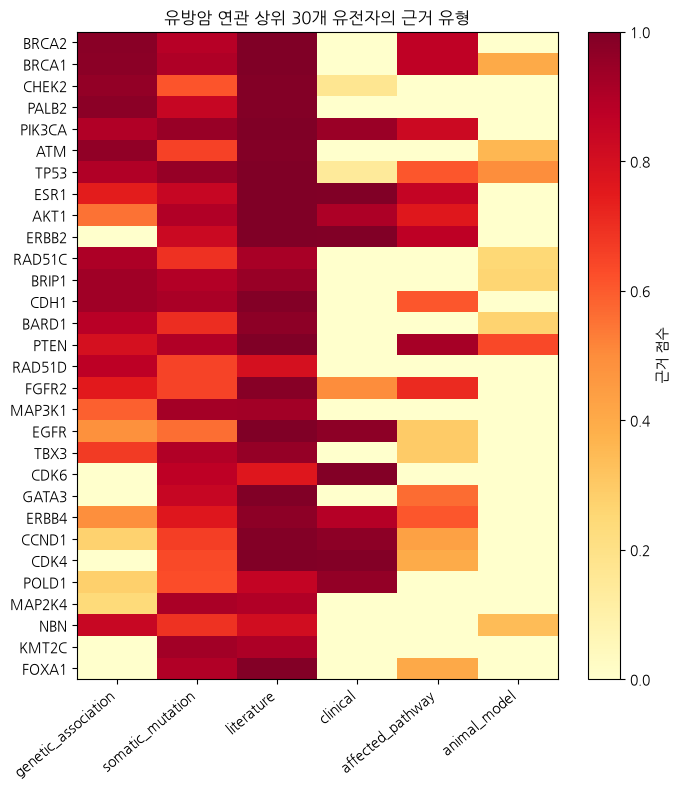

승인 약물이 이미 있는 표적: PIK3CA, ESR1, ERBB2, FGFR2, EGFR, CDK6, ERBB4, CDK4, POLD1, POLE, AR, KRAS, KDR, TOP1, PRIM1


In [3]:
ev_cols = [c for c in ["genetic_association", "somatic_mutation", "literature", "clinical", "affected_pathway", "animal_model"] if c in ot.columns]
top30 = ot.head(30).set_index("symbol")[ev_cols].fillna(0)
plt.figure(figsize=(7, 8)); plt.imshow(top30.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
plt.xticks(range(len(ev_cols)), ev_cols, rotation=40, ha="right"); plt.yticks(range(30), top30.index)
plt.colorbar(label="근거 점수"); plt.title("유방암 연관 상위 30개 유전자의 근거 유형"); plt.tight_layout(); plt.show()
print("승인 약물이 이미 있는 표적:", ", ".join(ot.loc[ot["approved_drug"], "symbol"].head(15)))

## 2. 환자 전사체 데이터 — TCGA 유방암 RNA-seq
**TCGA(The Cancer Genome Atlas)** BRCA PanCancer Atlas 의 환자 981명 종양 RNA-seq 중, 위 연관 유전자 + PAM50 아형 유전자 + 주요 표적 유전자 364개를 사용합니다 (값: log2(RSEM+1)).
**PAM50 분자아형**: Luminal A / Luminal B / HER2-enriched / **Basal-like(대부분 TNBC)** / Normal-like

> 아래 셀은 **cBioPortal API** 로 실시간 조회하는 방법을 보여줍니다 (유전자 3개). 전체 데이터는 수업용 스냅샷을 사용합니다.

In [4]:
B = "https://www.cbioportal.org/api"
try:
    g = requests.post(B + "/genes/fetch?geneIdType=HUGO_GENE_SYMBOL", json=["ESR1", "ERBB2", "FOXM1"], timeout=60).json()
    recs = requests.post(B + "/molecular-profiles/brca_tcga_pan_can_atlas_2018_rna_seq_v2_mrna/molecular-data/fetch",
                         json={"entrezGeneIds": [x["entrezGeneId"] for x in g], "sampleListId": "brca_tcga_pan_can_atlas_2018_all"}, timeout=120).json()
    print(f"[cBioPortal 실시간] {len(recs)}개 측정값 수신. 예:", {k: recs[0][k] for k in ['sampleId', 'entrezGeneId', 'value']})
except Exception as e:
    print("cBioPortal 응답 없음 (스냅샷으로 진행):", e)

ex = load_data("tcga_brca_expression_subset.csv.gz", index_col=0)
genes = [c for c in ex.columns if c != "subtype"]
print("환자 × 유전자:", ex[genes].shape)
print(ex["subtype"].value_counts().to_dict())

[cBioPortal 실시간] 3246개 측정값 수신. 예: {'sampleId': 'TCGA-3C-AAAU-01', 'entrezGeneId': 2305, 'value': 1313.95}
환자 × 유전자: (981, 364)
{'LumA': 499, 'LumB': 197, 'Basal': 171, 'Her2': 78, 'Normal': 36}


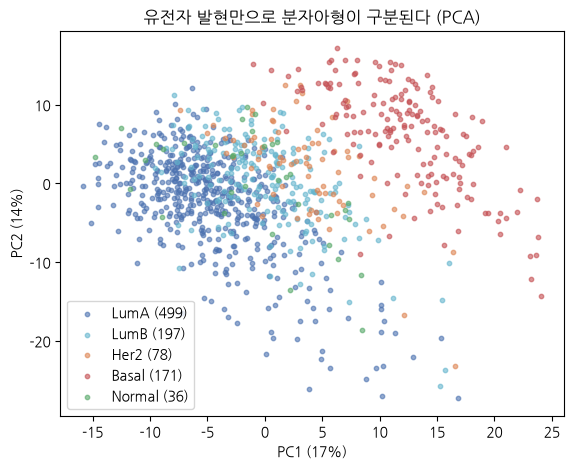

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(ex[genes])
pc = PCA(2).fit(Z); P = pc.transform(Z)
colors = {"LumA": "#4C72B0", "LumB": "#64B5CD", "Her2": "#DD8452", "Basal": "#C44E52", "Normal": "#55A868"}
plt.figure(figsize=(6.5, 5))
for s, c in colors.items():
    m = ex["subtype"] == s; plt.scatter(P[m, 0], P[m, 1], s=10, alpha=0.6, color=c, label=f"{s} ({m.sum()})")
plt.xlabel(f"PC1 ({pc.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pc.explained_variance_ratio_[1]:.0%})")
plt.legend(); plt.title("유전자 발현만으로 분자아형이 구분된다 (PCA)"); plt.show()

## 3. ⭐ 차등발현 분석 — Basal-like vs Luminal
각 유전자에 대해 두 그룹의 평균 차이(**log2 Fold Change**)와 통계적 유의성(**Welch t-검정 p-value**)을 계산하고,
수백 개 유전자를 동시에 검정하므로 **다중검정 보정(Benjamini-Hochberg FDR)** 을 합니다.

In [6]:
basal = ex[ex["subtype"] == "Basal"][genes]
lum = ex[ex["subtype"].isin(["LumA", "LumB"])][genes]
t, p = stats.ttest_ind(basal, lum, equal_var=False)

def bh_fdr(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

de = pd.DataFrame({"log2FC": basal.mean() - lum.mean(), "p": p, "FDR": bh_fdr(p)}, index=genes)
de["-log10FDR"] = -np.log10(de["FDR"].clip(lower=1e-300))
up = de[(de.log2FC > 1) & (de.FDR < 1e-5)].sort_values("log2FC", ascending=False)
down = de[(de.log2FC < -1) & (de.FDR < 1e-5)].sort_values("log2FC")
print(f"Basal 에서 증가 {len(up)}개, 감소 {len(down)}개 (|log2FC|>1, FDR<1e-5)")
print("증가 상위:", list(up.index[:15])); print("감소 상위:", list(down.index[:10]))

Basal 에서 증가 79개, 감소 51개 (|log2FC|>1, FDR<1e-5)
증가 상위: ['GABRP', 'KRT16', 'ELF5', 'BCL11A', 'MIA', 'KRT6A', 'EN1', 'SOX10', 'FOXC1', 'SFRP1', 'KRT5', 'KRT17', 'FOLR1', 'CDH3', 'CCNE1']
감소 상위: ['ESR1', 'FOXA1', 'ERBB4', 'PGR', 'MLPH', 'AR', 'PTPRT', 'NAT1', 'AFF3', 'MAPT']


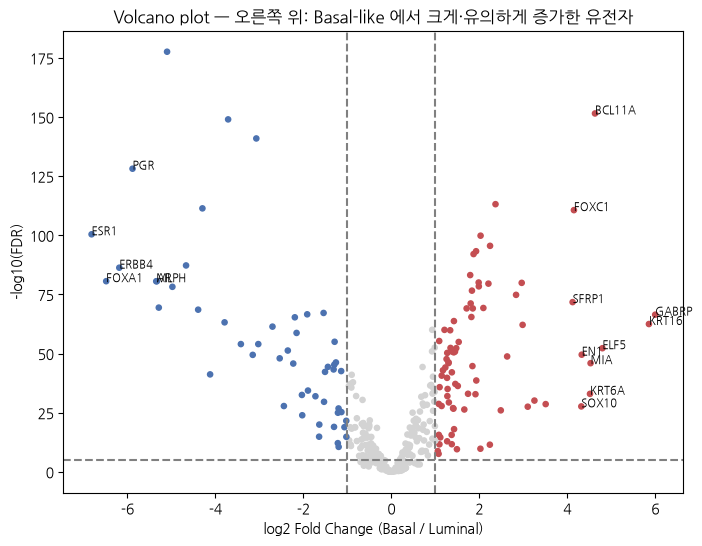

In [7]:
plt.figure(figsize=(8, 6))
c = np.where((de.log2FC > 1) & (de.FDR < 1e-5), "#C44E52", np.where((de.log2FC < -1) & (de.FDR < 1e-5), "#4C72B0", "lightgray"))
plt.scatter(de["log2FC"], de["-log10FDR"], c=c, s=14)
for gname in list(up.index[:10]) + list(down.index[:6]):
    plt.annotate(gname, (de.loc[gname, "log2FC"], de.loc[gname, "-log10FDR"]), fontsize=8)
plt.axvline(1, ls="--", c="gray"); plt.axvline(-1, ls="--", c="gray"); plt.axhline(5, ls="--", c="gray")
plt.xlabel("log2 Fold Change (Basal / Luminal)"); plt.ylabel("-log10(FDR)")
plt.title("Volcano plot — 오른쪽 위: Basal-like 에서 크게·유의하게 증가한 유전자"); plt.show()

## 4. 머신러닝 아형 분류와 바이오마커
유전자 발현으로 5개 아형을 분류하는 모델을 만들고, 모델이 중요하게 본 유전자(바이오마커)를 확인합니다.

              precision    recall  f1-score   support

       Basal      0.994     0.977     0.985       171
        Her2      0.907     0.872     0.889        78
        LumA      0.945     0.922     0.933       499
        LumB      0.801     0.898     0.847       197
      Normal      0.867     0.722     0.788        36

    accuracy                          0.915       981
   macro avg      0.903     0.878     0.888       981
weighted avg      0.918     0.915     0.916       981



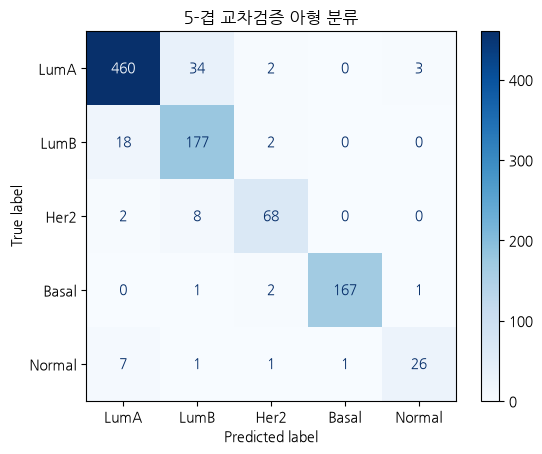

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0, class_weight="balanced")
pred = cross_val_predict(rf, ex[genes], ex["subtype"], cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(classification_report(ex["subtype"], pred, digits=3))
ConfusionMatrixDisplay.from_predictions(ex["subtype"], pred, labels=list(colors), cmap="Blues"); plt.title("5-겹 교차검증 아형 분류"); plt.show()

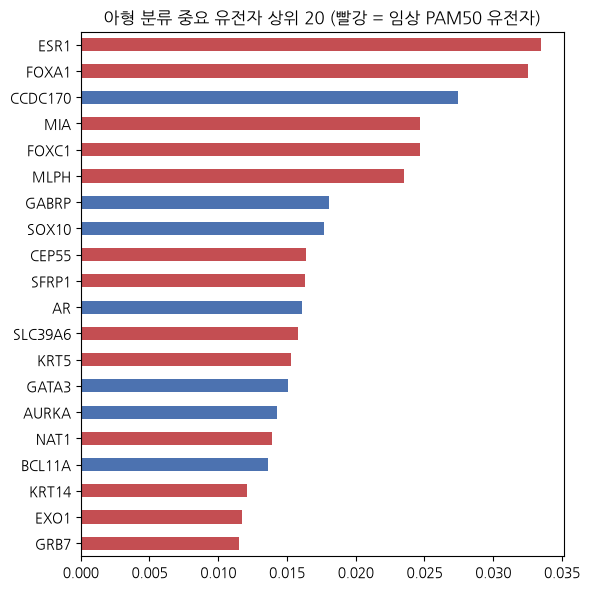

상위 20개 중 PAM50 유전자: 13개 → 데이터 기반으로 알려진 바이오마커를 재발견


In [9]:
rf.fit(ex[genes], ex["subtype"])
imp = pd.Series(rf.feature_importances_, index=genes).sort_values(ascending=False)
PAM50 = set("UBE2T BIRC5 NUF2 CDC6 CCNB1 TYMS MYBL2 CEP55 MELK NDC80 RRM2 UBE2C CENPF PTTG1 EXO1 ORC6 ANLN CCNE1 CDC20 MKI67 KIF2C ACTR3B MYC EGFR KRT5 PHGDH CDH3 MIA KRT17 FOXC1 SFRP1 KRT14 ESR1 SLC39A6 BAG1 MAPT PGR CXXC5 MLPH BCL2 MDM2 NAT1 FOXA1 BLVRA MMP11 GPR160 FGFR4 GRB7 TMEM45B ERBB2".split())
top = imp.head(20)
top.sort_values().plot.barh(figsize=(6, 6), color=["#C44E52" if gname in PAM50 else "#4C72B0" for gname in top.sort_values().index])
plt.title("아형 분류 중요 유전자 상위 20 (빨강 = 임상 PAM50 유전자)"); plt.tight_layout(); plt.show()
print(f"상위 20개 중 PAM50 유전자: {sum(gname in PAM50 for gname in top.index)}개 → 데이터 기반으로 알려진 바이오마커를 재발견")

## 5. ⭐ 단백질 상호작용(PPI) 네트워크 — 허브 유전자 찾기
Basal 에서 증가한 유전자들이 서로 어떻게 연결되는지 **STRING** 데이터베이스(신뢰도 ≥ 0.7)로 네트워크를 만들고,
**연결 중심성(degree)**·**매개 중심성(betweenness)** 으로 네트워크의 '허브'를 찾습니다.
- 허브 단백질 = 많은 신호가 지나가는 길목 → 억제 시 효과가 크지만, 정상세포 독성 위험도 함께 고려

In [10]:
cand = list(de[(de.log2FC > 0.8) & (de.FDR < 1e-5)].index)
try:
    r = requests.post("https://string-db.org/api/tsv/network", timeout=60,
                      data={"identifiers": "\r".join(cand), "species": 9606, "required_score": 700, "caller_identity": "snu_ai_course"})
    edges = pd.read_csv(io.StringIO(r.text), sep="\t")[["preferredName_A", "preferredName_B", "score"]]
    print("[STRING 실시간] 상호작용", len(edges), "개")
except Exception as e:
    snap = load_data("string_network_snapshot.csv")
    edges = snap[snap.preferredName_A.isin(cand) & snap.preferredName_B.isin(cand)]
    print("STRING 응답 없음 → 스냅샷 사용:", len(edges), "개")

G = nx.Graph(); G.add_nodes_from(cand)
G.add_weighted_edges_from(edges[["preferredName_A", "preferredName_B", "score"]].values)
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
deg, btw = nx.degree_centrality(G), nx.betweenness_centrality(G)
net = pd.DataFrame({"degree": pd.Series(dict(G.degree())), "degree_c": pd.Series(deg), "betweenness": pd.Series(btw)}).sort_values("degree", ascending=False)
print(f"네트워크: 노드 {G.number_of_nodes()}개, 엣지 {G.number_of_edges()}개")
net.head(10).round(3)

[STRING 실시간] 상호작용 440 개
네트워크: 노드 81개, 엣지 440개


,degree,degree_c,betweenness
CCNB1,32,0.400,0.059
PLK1,30,0.375,0.067
AURKB,27,0.338,0.032
CDC20,26,0.325,0.006
BIRC5,26,0.325,0.067
TOP2A,26,0.325,0.008
NUF2,26,0.325,0.025
MELK,25,0.312,0.016
RRM2,25,0.312,0.010
MYC,24,0.300,0.251


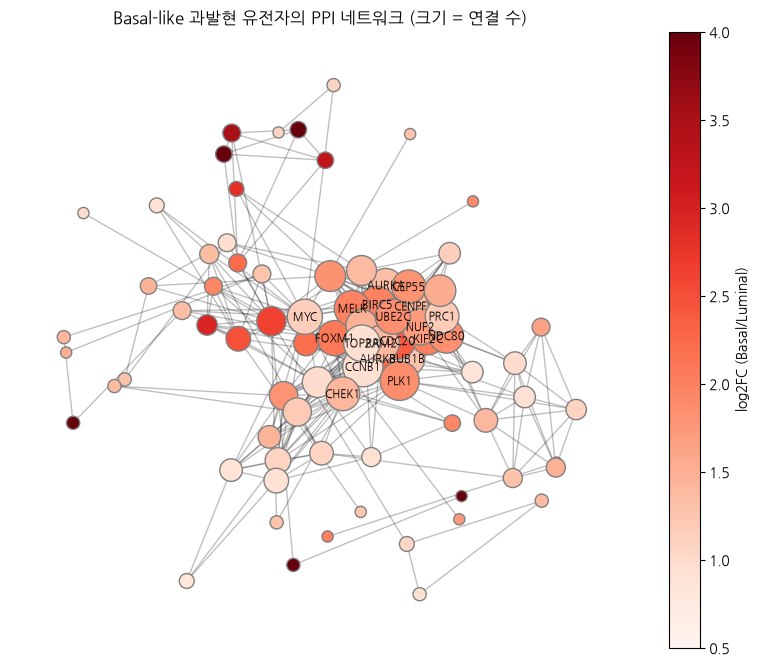

In [11]:
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=3, k=0.6)
fc = [de.loc[n, "log2FC"] for n in G]
nodes = nx.draw_networkx_nodes(G, pos, node_size=[40 + 25 * G.degree(n) for n in G], node_color=fc, cmap="Reds", vmin=0.5, vmax=4, edgecolors="gray")
nx.draw_networkx_edges(G, pos, alpha=0.25)
nx.draw_networkx_labels(G, pos, labels={n: n for n in net.index[:20]}, font_size=8, font_family="NanumGothic")
plt.colorbar(nodes, label="log2FC (Basal/Luminal)"); plt.title("Basal-like 과발현 유전자의 PPI 네트워크 (크기 = 연결 수)"); plt.axis("off"); plt.show()

## 6. ⭐ 근거 통합 타겟 우선순위
네 가지 근거를 0~1 로 정규화해 가중합합니다 (가중치는 연구 전략에 따라 조정).

| 근거 | 지표 | 가중치 |
|---|---|---|
| 질병 연관성 | Open Targets 점수 | 0.3 |
| 환자 발현 변화 | Basal 대비 log2FC 순위 | 0.3 |
| 네트워크 중심성 | degree 순위 | 0.2 |
| 약물개발 가능성 | 저분자 또는 항체 tractable | 0.2 |

In [12]:
pr = de[(de.log2FC > 0.8) & (de.FDR < 1e-5)].copy()
pr = pr.join(ot.set_index("symbol")[["ot_score", "sm_tractable", "ab_tractable", "approved_drug"]], how="left")
pr["ot_score"] = pr["ot_score"].fillna(0)
pr[["sm_tractable", "ab_tractable", "approved_drug"]] = pr[["sm_tractable", "ab_tractable", "approved_drug"]].fillna(False).astype(bool)
pr["degree"] = net["degree"].reindex(pr.index).fillna(0)
pr["score"] = (0.3 * pr["ot_score"].rank(pct=True) + 0.3 * pr["log2FC"].rank(pct=True)
               + 0.2 * pr["degree"].rank(pct=True) + 0.2 * (pr["sm_tractable"] | pr["ab_tractable"]))
rank = pr.sort_values("score", ascending=False)
rank.head(15)[["log2FC", "FDR", "ot_score", "degree", "sm_tractable", "ab_tractable", "approved_drug", "score"]].round(3)

,log2FC,FDR,ot_score,degree,sm_tractable,ab_tractable,approved_drug,score
EGFR,2.633,0.0,0.757,16.0,True,True,True,0.897
CDK6,1.931,0.0,0.744,5.0,True,False,True,0.811
RRM2,1.412,0.0,0.612,25.0,True,False,True,0.783
TYMS,1.376,0.0,0.628,17.0,True,False,True,0.755
TUBB3,1.659,0.0,0.632,5.0,True,False,True,0.753
TUBB2B,1.491,0.0,0.628,6.0,True,False,True,0.746
EXO1,1.804,0.0,0.550,15.0,True,True,False,0.744
TERT,1.371,0.0,0.707,6.0,True,False,False,0.734
TUBA4A,1.403,0.0,0.613,10.0,True,True,True,0.732
BLM,1.447,0.0,0.589,9.0,True,False,False,0.720


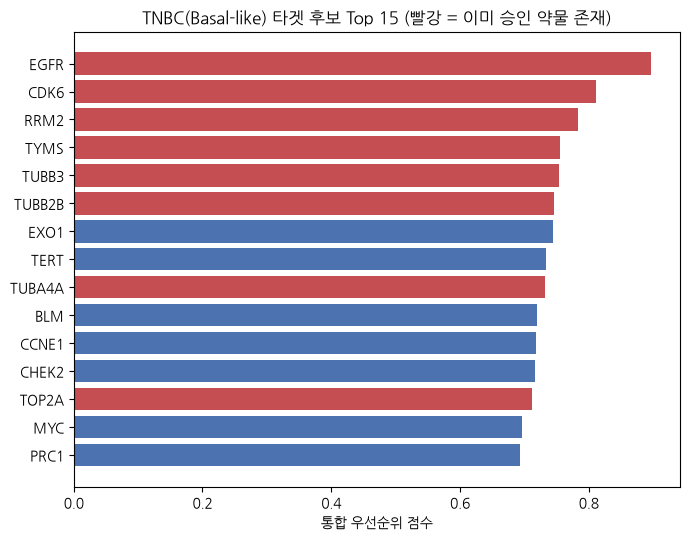

In [13]:
r15 = rank.head(15)[::-1]
plt.figure(figsize=(7, 5.5))
plt.barh(r15.index, r15["score"], color=["#C44E52" if a else "#4C72B0" for a in r15["approved_drug"]])
plt.xlabel("통합 우선순위 점수"); plt.title("TNBC(Basal-like) 타겟 후보 Top 15 (빨강 = 이미 승인 약물 존재)"); plt.tight_layout(); plt.show()

> **결과 해석 가이드**
> - 세포주기·증식 유전자(예: FOXM1, CCNB1, AURKA, PLK1 등)가 상위에 오르는 것은 Basal-like 의 **높은 증식성**을 반영합니다 — 표적으로는 강력하지만 **정상 증식세포 독성(골수억제)** 을 함께 고려해야 합니다.
> - **이미 승인 약물이 있는 표적**은 약물 재창출(repurposing)·병용 전략, **약물이 없지만 tractable 한 표적**은 신규(first-in-class) 기회입니다.
> - 이 점수는 **가설 생성 도구**입니다. 다음 단계: DepMap CRISPR 의존성, 정상조직 발현(GTEx), 문헌 검토 → 구조 확보(예제 08) → 가상 스크리닝(예제 07)

## 🧪 LLM 코딩 과제
```
위 노트북의 ex(유전자 발현, 'subtype' 열 포함) 데이터로 HER2-enriched(Her2) vs LumA 차등발현 분석을 해서
volcano plot 을 그리고, log2FC > 1, FDR < 1e-5 인 유전자 목록을 표로 보여줘. FDR 은 Benjamini-Hochberg 로 계산해줘.
```

In [14]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 & 현장 응용
- 타겟 발굴은 **여러 근거의 통합**: 유전학(Open Targets) + 환자 오믹스(TCGA) + 네트워크(STRING) + 약물개발 가능성
- **차등발현 분석**: log2FC + 다중검정 보정(FDR) → volcano plot
- **머신러닝 분류**는 아형·바이오마커 발굴에, **네트워크 중심성**은 핵심 조절자(허브) 탐색에 활용
- 최신 동향: 단일세포(scRNA-seq)·공간전사체, 유전체 파운데이션 모델(Geneformer, scGPT), **멀티오믹스 통합 AI**, 지식그래프 기반 타겟 추론, **연합학습**(여러 기관 데이터를 공유 없이 학습, 예: MELLODDY/K-MELLODDY)

➡️ **다음 예제 10**: 표적이 정해졌다면 — **생성형 AI 로 새로운 후보 분자 설계**